# Домашнее задание №6. Кластеризация и SVM

## Ф.И.О: Чайкин Владимир Денисович

В этом домашнем задании вам предстоит собственноручно написать методы кластеризации и метод опорных векторов. В качестве вспомогательных материалов мы прилагаем ссылки на статьи и ресурсы, которые содержат подробную информацию о представленных алгоритмах.

#### Полезные ссылки:

1. [Описание](https://scikit-learn.org/stable/modules/clustering.html#k-means) K-means от scikit-learn
2. Статья по алгоритму [K-means++](https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf)
3. Статья по алгоритму [DBSCAN](https://cdn.aaai.org/KDD/1996/KDD96-037.pdf)
4. Статья по алгоритму [SVM](https://link.springer.com/content/pdf/10.1007/bf00994018.pdf)
5. [Описание](https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html) параметров Radial Basis Function (RBF) от scikit-learn

In [5]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import adjusted_rand_score, accuracy_score
from sklearn.datasets import load_iris, make_classification, make_moons
from cvxopt import matrix, solvers

### __1__. Реализация алгортима K-means (6 points)

----------------------------

#### __1.1__. Реализуйте алгоритм K-means без использования библиотек с реализацией данного метода (по типу библиотеки sklearn) (3 points)

In [13]:
def k_means(X, k, max_iters=3, tol=1e-4):
    np.random.seed(42)
    n_samples, n_features = X.shape
    centroids = X[np.random.choice(n_samples, k, replace=False)]
    
    for iteration in range(max_iters):
        # Вычисляем расстояния от каждой точки до каждого центроида
        distances = np.zeros((n_samples, k))
        for i in range(k):
            distances[:, i] = np.linalg.norm(X - centroids[i], axis=1)
        
        # Назначаем каждой точке ближайший центроид
        labels = np.argmin(distances, axis=1)
        
        #Обновление центроидов
        new_centroids = np.zeros((k, n_features))
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                new_centroids[i] = cluster_points.mean(axis=0)
            else:
                new_centroids[i] = X[np.random.randint(0, n_samples)]
        
        # Проверка сходимости
        centroid_shift = np.linalg.norm(new_centroids - centroids, axis=1).max()
        centroids = new_centroids
        
        if centroid_shift < tol:
            break
    
    distances = np.zeros((n_samples, k))
    for i in range(k):
        distances[:, i] = np.linalg.norm(X - centroids[i], axis=1)
    labels = np.argmin(distances, axis=1)
    
    inertia = 0
    for i in range(k):
        cluster_points = X[labels == i]
        if len(cluster_points) > 0:
            inertia += np.sum(np.linalg.norm(cluster_points - centroids[i], axis=1)**2)
    
    return labels, centroids


# Automatic Checker
def check_k_means():
    iris = load_iris()
    X = iris.data
    y_true = iris.target

    labels_custom, centroids_custom = k_means(X, k=3)
    kmeans_sklearn = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
    labels_sklearn = kmeans_sklearn.labels_

    score_custom = adjusted_rand_score(y_true, labels_custom)
    score_sklearn = adjusted_rand_score(y_true, labels_sklearn)
    print(score_custom)
    print(score_sklearn)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.scatter(X[:, 0], X[:, 1], c=labels_custom, cmap='viridis', marker='o')
    plt.scatter(centroids_custom[:, 0], centroids_custom[:, 1], s=300, c='red', marker='X')
    plt.title('K-Means Clustering')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')

    assert labels_custom is not None, "Function should return labels."
    assert len(labels_custom) == len(X), "Should return labels for all points."
    assert score_custom > 0.7, "Clustering should achieve a higher score."
    print(f"Task 1.1 Passed! Adjusted Rand Score: {score_custom:.2f}")

0.7311985567707746
0.7302382722834697
Task 1.1 Passed! Adjusted Rand Score: 0.73


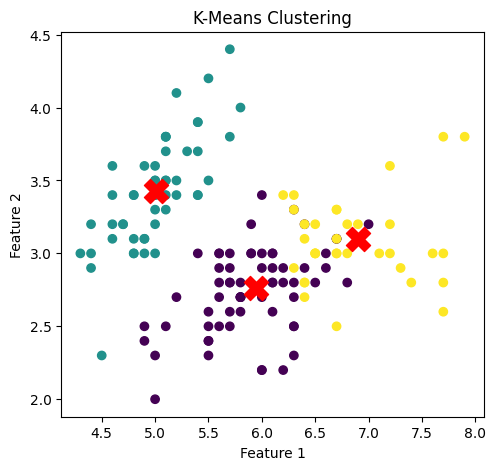

In [14]:
check_k_means()

#### __1.2__. Реализуйте алгоритм K-means++ без использования библиотек с реализацией данного метода (3 points)

In [17]:
def initialize_plus_plus(X, k):
    np.random.seed(42)
    n_samples, n_features = X.shape
    
    # Первый центроид выбираем случайно
    centroids = [X[np.random.randint(n_samples)]]
    
    # Выбираем остальные k-1 центроидов
    for _ in range(1, k):
        distances = np.array([min([np.linalg.norm(x - c)**2 for c in centroids]) for x in X])
        probabilities = distances / distances.sum()
        cumulative_probs = probabilities.cumsum()
        r = np.random.rand()
        for i, cum_prob in enumerate(cumulative_probs):
            if r <= cum_prob:
                centroids.append(X[i])
                break
    
    return np.array(centroids)

def k_means_plus_plus(X, k, max_iters=100, tol=1e-4):
    centroids = initialize_plus_plus(X, k)
    
    n_samples, n_features = X.shape
    
    for iteration in range(max_iters):
        distances = np.zeros((n_samples, k))
        for i in range(k):
            distances[:, i] = np.linalg.norm(X - centroids[i], axis=1)
        
        labels = np.argmin(distances, axis=1)
        
        new_centroids = np.zeros((k, n_features))
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                new_centroids[i] = cluster_points.mean(axis=0)
            else:
                new_centroids[i] = X[np.random.randint(0, n_samples)]
        
        # Проверка сходимости
        centroid_shift = np.linalg.norm(new_centroids - centroids, axis=1).max()
        centroids = new_centroids
        
        if centroid_shift < tol:
            break
    
    # Вычисляем финальные метки
    distances = np.zeros((n_samples, k))
    for i in range(k):
        distances[:, i] = np.linalg.norm(X - centroids[i], axis=1)
    labels = np.argmin(distances, axis=1)
    
    return labels, centroids

# Automatic Checker
def check_k_means_plus_plus():
    iris = load_iris()
    X = iris.data
    y_true = iris.target

    labels_custom, centroids_custom = k_means_plus_plus(X, k=3)
    kmeans_sklearn = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10).fit(X)
    labels_sklearn = kmeans_sklearn.labels_

    score_custom = adjusted_rand_score(y_true, labels_custom)
    score_sklearn = adjusted_rand_score(y_true, labels_sklearn)
    print(score_custom)
    print(score_sklearn)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.scatter(X[:, 0], X[:, 1], c=labels_custom, cmap='viridis', marker='o')
    plt.scatter(centroids_custom[:, 0], centroids_custom[:, 1], s=300, c='red', marker='X')
    plt.title('K-Means++ Clustering')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')

    assert labels_custom is not None, "Function should return labels."
    assert len(labels_custom) == len(X), "Should return labels for all points."
    assert score_custom > 0.7, "Clustering should achieve a higher score."
    print(f"Task 1.2 Passed! Adjusted Rand Score: {score_custom:.2f}")


0.7163421126838476
0.7302382722834697
Task 1.2 Passed! Adjusted Rand Score: 0.72


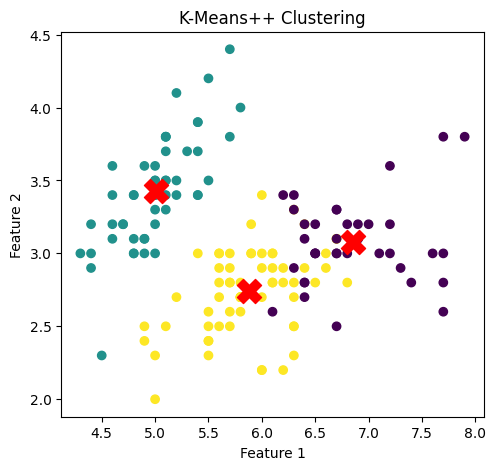

In [18]:
check_k_means_plus_plus()

### __2__. Оценка алгоритма DBSCAN (4 points)

Предположим, что вы анализируете движение такси в городе, чтобы определить популярные зоны посадки. У вас есть набор данных, представляющий места посадки такси.

```
data_points = [
    (1.2, 3.1), (2.5, 3.3), (1.8, 2.9), (8.2, 7.5),
    (8.1, 7.7), (25.3, 80.2), (2.0, 3.0), (3.0, 3.5),
    (1.1, 1.2), (90.0, 91.2), (1.5, 3.2), (8.0, 7.6),
    (2.2, 3.1), (7.9, 7.8), (1.3, 3.0)
]
```

Каждая точка представляет место посадки в такси с координатами (x, y) км от центра города.

С помощью алгортима DBSCAN сгруппируйте эти поездки на такси, чтобы определить зоны с высокой плотностью посадки. Укажите, какие из точек core, а какие являются выбросами.

Указание: выберите максимальное расстояние между точками равным __1.5__ и минимальное число точек в группе равным __3__.

Для решения этой задачи не используйте библиотеки с реализацией DBSCAN.

In [21]:
import numpy as np
import math

def dbscan(data, eps, min_pts):

    n = len(data)
    labels = [-1] * n
    point_types = ['noise'] * n
    cluster_id = 0
    
    def euclidean_distance(point1, point2):
        return math.sqrt((point1[0] - point2[0])**2 + (point1[1] - point2[1])**2)
    
    def region_query(point_idx):
        neighbors = []
        for i in range(n):
            if euclidean_distance(data[point_idx], data[i]) <= eps:
                neighbors.append(i)
        return neighbors
    
    def expand_cluster(point_idx, neighbors, cluster_id):
        labels[point_idx] = cluster_id
        i = 0
        while i < len(neighbors):
            neighbor_idx = neighbors[i]

            if labels[neighbor_idx] == -1:
                labels[neighbor_idx] = cluster_id
                new_neighbors = region_query(neighbor_idx)
    
                if len(new_neighbors) >= min_pts:
                    for new_idx in new_neighbors:
                        if new_idx not in neighbors:
                            neighbors.append(new_idx)
        
            i += 1
    
    # Основной алгоритм DBSCAN
    for i in range(n):
        if labels[i] != -1:
            continue
            
        neighbors = region_query(i)
        
        if len(neighbors) < min_pts:
            labels[i] = -1
            point_types[i] = 'noise'
        else:
            cluster_id += 1
            point_types[i] = 'core'
            expand_cluster(i, neighbors, cluster_id)
    
    # Определяем типы точек после кластеризации
    for i in range(n):
        if point_types[i] == 'core':
            continue
            
        neighbors = region_query(i)
        core_neighbors = [j for j in neighbors if point_types[j] == 'core']
        
        if labels[i] != -1 and len(core_neighbors) > 0:
            point_types[i] = 'border'
        elif labels[i] == -1:
            point_types[i] = 'noise'
    
    return labels, point_types

data_points = [
    (1.2, 3.1), (2.5, 3.3), (1.8, 2.9), (8.2, 7.5),
    (8.1, 7.7), (25.3, 80.2), (2.0, 3.0), (3.0, 3.5),
    (1.1, 1.2), (90.0, 91.2), (1.5, 3.2), (8.0, 7.6),
    (2.2, 3.1), (7.9, 7.8), (1.3, 3.0)
]

eps = 1.5
min_pts = 3

labels, point_types = dbscan(data_points, eps, min_pts)

# Анализируем результаты
print("Результаты кластеризации DBSCAN:")
print("Параметры: eps = 1.5, min_pts = 3")

clusters = {}
for i, (point, label, p_type) in enumerate(zip(data_points, labels, point_types)):
    if label not in clusters:
        clusters[label] = []
    clusters[label].append((i, point, p_type))

# Выводим результаты по кластерам
for cluster_id in sorted(clusters.keys()):
    points = clusters[cluster_id]
    if cluster_id == -1:
        print(f"\nВыбросы:")
    else:
        print(f"\nКластер {cluster_id}:")
    
    for idx, point, p_type in points:
        print(f"Точка {idx}: {point} - {p_type}")

# Статистика
print(f"\nВсего точек: {len(data_points)}")
print(f"Найдено кластеров: {len([x for x in clusters.keys() if x != -1])}")
print(f"Core точек: {sum(1 for t in point_types if t == 'core')}")
print(f"Border точек: {sum(1 for t in point_types if t == 'border')}")
print(f"Выбросов: {sum(1 for t in point_types if t == 'noise')}")

Результаты кластеризации DBSCAN:
Параметры: eps = 1.5, min_pts = 3

Выбросы:
Точка 5: (25.3, 80.2) - noise
Точка 8: (1.1, 1.2) - noise
Точка 9: (90.0, 91.2) - noise

Кластер 1:
Точка 0: (1.2, 3.1) - core
Точка 1: (2.5, 3.3) - border
Точка 2: (1.8, 2.9) - border
Точка 6: (2.0, 3.0) - border
Точка 7: (3.0, 3.5) - noise
Точка 10: (1.5, 3.2) - border
Точка 12: (2.2, 3.1) - border
Точка 14: (1.3, 3.0) - border

Кластер 2:
Точка 3: (8.2, 7.5) - core
Точка 4: (8.1, 7.7) - border
Точка 11: (8.0, 7.6) - border
Точка 13: (7.9, 7.8) - border

Всего точек: 15
Найдено кластеров: 2
Core точек: 2
Border точек: 9
Выбросов: 4


### __3__. (Доп.) Оценка алгоритма SVM (5 points)

Рассмотрим набор данных в 2D-пространстве, где первые два значения - это координаты точек, а третье значение - метка класса:

```
data_points = [
    (-4, 2, 1), (-1, -1, -1), (0, -2, -1), (1, -2, -1),
    (2, 3, 1), (3, 3, 1), (4, 4, 1), (-4, -3, -1), (-5, -2, -1),
    (5, 2, 1), (6, 1, 1), (-6, -1, -1), (-7, -3, -1), (7, 3, 1),
    (8, 4, 1), (-8, -5, -1), (9, 5, 1), (-9, -4, -1), (10, 6, 1),
]
```

1. Определите уравнение прямой, которая наилучшим образом разделяет два класса
2. Определите величину зазора (margin) и вектор, ортогональный разделяющей границе
3. Определите, какие точки являются опорными векторами

Указание: в данной задаче необходимо преобразовать двойственную задачу SVM к стандартному виду квадратичной задачи и использовать солвер (см. импорты и [документацию cvxopt](https://cvxopt.org/examples/tutorial/qp.html)), чтобы восстановить разделяющую гиперплоскость и опорные вектора.


Уравнение разделяюкщей прямой:
0.0741*x1 + 0.7407*x2 + -0.1852 = 0
Вектор w: [0.0741, 0.7407]
Норма вектора w: ||w|| = 0.7444
Величина зазора (margin): 2/||w|| = 2.6866

Опорные векторы:
Индексы | Альфа-значения | Координаты | Метка
      0 |      0.186557 | ( -4,   2) |   1
      1 |      0.277092 | ( -1,  -1) |  -1
     10 |      0.090535 | (  6,   1) |   1


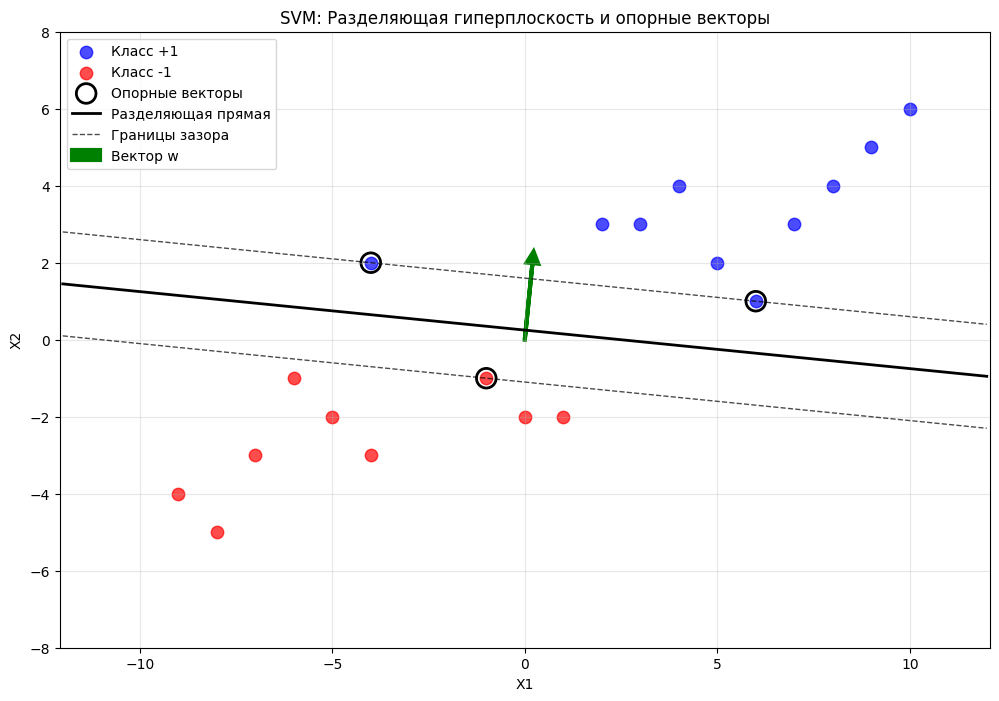


Точность классификации: 19/19 = 100.0%


In [27]:
import numpy as np
from cvxopt import matrix, solvers
import matplotlib.pyplot as plt

data_points = [
    (-4, 2, 1), (-1, -1, -1), (0, -2, -1), (1, -2, -1),
    (2, 3, 1), (3, 3, 1), (4, 4, 1), (-4, -3, -1), (-5, -2, -1),
    (5, 2, 1), (6, 1, 1), (-6, -1, -1), (-7, -3, -1), (7, 3, 1),
    (8, 4, 1), (-8, -5, -1), (9, 5, 1), (-9, -4, -1), (10, 6, 1),
]

X = np.array([point[:2] for point in data_points])
y = np.array([point[2] for point in data_points])


def solve_svm_dual(X, y):

    n_samples, _ = X.shape
    
    K = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            K[i, j] = y[i] * y[j] * np.dot(X[i], X[j])
    
    P = matrix(K)
    q = matrix(-np.ones(n_samples))
    
    G = matrix(-np.eye(n_samples))
    h = matrix(np.zeros(n_samples))
    
    A = matrix(y.astype(float).reshape(1, -1))
    b = matrix(0.0)
    
    solvers.options['show_progress'] = False
    solution = solvers.qp(P, q, G, h, A, b)
    alphas = np.array(solution['x']).flatten()
    
    return alphas

def get_svm_params(X, y, alphas):
    # Находим опорные векторы (alpha > 1e-5)
    support_vectors_idx = alphas > 1e-5
    support_vectors = X[support_vectors_idx]
    support_alphas = alphas[support_vectors_idx]
    support_labels = y[support_vectors_idx]
    
    # Вычисляем веса w
    w = np.zeros(2)
 
    for i in range(len(support_vectors)):
        w += support_alphas[i] * support_labels[i] * support_vectors[i]
    
    # Вычисляем смещение b
    b = 0
    for i in range(len(support_vectors)):
        b += support_labels[i] - np.dot(w, support_vectors[i])
    b /= len(support_vectors)
    
    return w, b, support_vectors_idx, support_vectors, support_alphas

# Решаем задачу SVM
alphas = solve_svm_dual(X, y)
w, b, support_vectors_idx, support_vectors, support_alphas = get_svm_params(X, y, alphas)


print("\nУравнение разделяюкщей прямой:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + {b:.4f} = 0")

w_norm = np.linalg.norm(w)
margin = 2 / w_norm
print(f"Вектор w: [{w[0]:.4f}, {w[1]:.4f}]")
print(f"Норма вектора w: ||w|| = {w_norm:.4f}")
print(f"Величина зазора (margin): 2/||w|| = {margin:.4f}")

print("\nОпорные векторы:")
print("Индексы | Альфа-значения | Координаты | Метка")
for i, idx in enumerate(np.where(support_vectors_idx)[0]):
    alpha_val = alphas[idx]
    point = X[idx]
    label = y[idx]
    print(f"{idx:7d} | {alpha_val:13.6f} | ({point[0]:3.0f}, {point[1]:3.0f}) | {label:3.0f}")

# Визуализация
plt.figure(figsize=(12, 8))

class_1 = X[y == 1]
class_minus_1 = X[y == -1]

plt.scatter(class_1[:, 0], class_1[:, 1], c='blue', s=80, label='Класс +1', alpha=0.7)
plt.scatter(class_minus_1[:, 0], class_minus_1[:, 1], c='red', s=80, label='Класс -1', alpha=0.7)

support_points = X[support_vectors_idx]
plt.scatter(support_points[:, 0], support_points[:, 1], 
           facecolors='none', edgecolors='black', s=200, linewidth=2, label='Опорные векторы')

x_min, x_max = -12, 12
x_plot = np.linspace(x_min, x_max, 100)
if abs(w[1]) > 1e-10:
    y_plot = (-w[0] * x_plot - b) / w[1]
    plt.plot(x_plot, y_plot, 'k-', linewidth=2, label='Разделяющая прямая')

    y_plot_margin1 = (-w[0] * x_plot - b + 1) / w[1]
    y_plot_margin2 = (-w[0] * x_plot - b - 1) / w[1]
    plt.plot(x_plot, y_plot_margin1, 'k--', linewidth=1, alpha=0.7, label='Границы зазора')
    plt.plot(x_plot, y_plot_margin2, 'k--', linewidth=1, alpha=0.7)
else:
    x_line = -b / w[0]
    plt.axvline(x=x_line, color='k', linewidth=2, label='Разделяющая прямая')

w_scale = 2 / w_norm
plt.arrow(0, 0, w[0] * w_scale, w[1] * w_scale, 
          head_width=0.3, head_length=0.3, fc='green', ec='green', linewidth=3, label='Вектор w')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('SVM: Разделяющая гиперплоскость и опорные векторы')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.legend()
plt.xlim(x_min, x_max)
plt.ylim(-8, 8)
plt.show()


correct = 0
for i, (point, true_label) in enumerate(zip(X, y)):
    prediction = np.sign(np.dot(w, point) + b)
    if prediction == true_label:
        correct += 1

print(f"\nТочность классификации: {correct}/{len(X)} = {correct/len(X)*100:.1f}%")

### __4__. Реализация алгоритма SVM (10 points)

----------------------------

#### __4.1__. Реализуйте алгоритм Linear SVM без использования библиотек с реализацией данного метода (5 points)

In [30]:
from sklearn.datasets import make_classification
def linear_svm(X, y, learning_rate=0.001, lambda_param=0.01, n_iters=1000):
    """ Реализуйте Linear SVM """
    np.random.seed(42)
    n_samples, n_features = X.shape
    weights = np.random.randn(n_features) * 0.01
    bias = 0
    
    for epoch in range(n_iters):
        total_loss = 0
        grad_w = np.zeros_like(weights)
        grad_b = 0
        
        for i in range(n_samples):
            prediction = np.dot(X[i], weights) - bias
            margin = y[i] * prediction
            
            if margin >= 1:
                grad_w += 2 * lambda_param * weights
            else:
                grad_w += 2 * lambda_param * weights - y[i] * X[i]
                grad_b += -y[i]
                total_loss += 1 - margin
        
        # Средний градиент по всем примерам
        grad_w /= n_samples
        grad_b /= n_samples
        
        # Обновление параметров
        weights -= learning_rate * grad_w
        bias -= learning_rate * grad_b
        
        reg_loss = lambda_param * np.sum(weights ** 2)
        total_loss = total_loss / n_samples + reg_loss
        
        if epoch % 200 == 0:
            print(f"Epoch {epoch}, Loss: {total_loss:.4f}")
    
    return weights, bias

def predict_svm(X, weights, bias):
    return np.sign(np.dot(X, weights) - bias)

# Automatic Checker
def check_linear_svm():
    X, y = make_classification(n_samples=1000, n_features=4, n_informative=2, n_redundant=0, random_state=42)
    y = np.where(y == 0, -1, 1)

    X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

    weights, bias = linear_svm(X, y)
    y_pred = predict_svm(X, weights, bias)

    svm_sklearn = SVC(kernel='linear', random_state=42)
    svm_sklearn.fit(X, y)
    y_pred_sklearn = svm_sklearn.predict(X)

    accuracy = accuracy_score(y, y_pred)
    accuracy_sklearn = accuracy_score(y, y_pred_sklearn)

    assert accuracy > 0.85, "Accuracy should be higher"
    print(f"Task 4.1 Passed! Accuracy: {accuracy:.2f}")

In [31]:
check_linear_svm()

Epoch 0, Loss: 0.9961
Epoch 200, Loss: 0.8927
Epoch 400, Loss: 0.7900
Epoch 600, Loss: 0.6931
Epoch 800, Loss: 0.6173
Task 4.1 Passed! Accuracy: 0.87


#### __4.2__. Реализуйте Kernel SVM с использованием RBF ядра без использования библиотек с реализацией данного метода (5 points)

In [34]:
def rbf_kernel(X, Y=None, gamma=0.1):
    if Y is None:
        Y = X
    X_norm = np.sum(X**2, axis=1, keepdims=True)
    Y_norm = np.sum(Y**2, axis=1, keepdims=True)
    distances_sq = X_norm + Y_norm.T - 2 * np.dot(X, Y.T)
    K = np.exp(-gamma * distances_sq)
    return K

def kernel_svm(X, y, gamma=0.1, learning_rate=0.001, lambda_param=0.01, n_iters=1000):
    np.random.seed(42)
    
    n_samples = X.shape[0]
    
    K = rbf_kernel(X, X, gamma)

    alpha = np.random.randn(n_samples) * 0.01
    
    # Градиентный спуск для двойственной задачи
    for epoch in range(n_iters):
        total_loss = 0
        
        for i in range(n_samples):
            prediction = np.sum(alpha * y * K[i, :])
            
            # Условие KKT для SVM
            if y[i] * prediction >= 1:
                grad_alpha = 2 * lambda_param * alpha[i]
            else:
                grad_alpha = 2 * lambda_param * alpha[i] - 1
            
            alpha[i] -= learning_rate * grad_alpha
            alpha[i] = max(0, alpha[i])
        
        if epoch % 200 == 0:
            hinge_loss = np.sum(np.maximum(0, 1 - y * np.dot(K, alpha * y)))
            reg_loss = lambda_param * np.dot(alpha, np.dot(K, alpha))
            total_loss = hinge_loss / n_samples + reg_loss
            print(f"Epoch {epoch}, Loss: {total_loss:.4f}")
    
    return alpha


def predict_kernel_svm(X, X_train, y_train, alpha, gamma=0.1):
    K = rbf_kernel(X, X_train, gamma)
    return np.sign(np.dot(K, alpha * y_train))

# Automatic Checker
def check_kernel_svm():
    X, y = make_moons(n_samples=50, noise=0.01, random_state=42)
    y = np.where(y == 0, -1, 1)

    alpha = kernel_svm(X, y)
    y_pred = predict_kernel_svm(X, X, y, alpha)

    svm_sklearn = SVC(kernel='rbf', gamma=0.1, random_state=42)
    svm_sklearn.fit(X, y)
    y_pred_sklearn = svm_sklearn.predict(X)

    accuracy = accuracy_score(y, y_pred)
    accuracy_sklearn = accuracy_score(y, y_pred_sklearn)

    print(accuracy_sklearn)

    assert accuracy > 0.8, "Accuracy should be higher"
    print(f"Task 4.2 Passed! Accuracy: {accuracy:.2f}")

In [35]:
check_kernel_svm()

Epoch 0, Loss: 0.9921
Epoch 200, Loss: 1.2896
Epoch 400, Loss: 2.5592
Epoch 600, Loss: 4.1512
Epoch 800, Loss: 6.0615
0.84
Task 4.2 Passed! Accuracy: 0.84
